This code contains the plotting recipies for the paper "Reconciling the tempo and timing of eukaryote emergence 
with Clade Dynamics and the Fossil Record" by Corentin Loron and Niall Rodgers. All plotted equations should be consistent with the equations given in the main text. 

In [1]:
# ============================================================
# GLOBAL SETTINGS — edit this cell, then rerun the figure cells
# ============================================================

# Grid resolution: 

GRID_SIZE = 3000
T_MIN, T_MAX = 1100, 3500
TCG_MIN, TCG_MAX = 600, 2100

# Model parameters
RHOS = [0.1, 0.9, 0.99]
K_OBS = 2.5e6                 # observed modern diversity
N_OBS = K_OBS                 # same target for the exact gap calculation
P_FLOOR = 1e-12               # implied-rate probability treated as zero below this
GAP_P_FLOOR = 1e-6            # exact gap probability treated as zero below this

# Colour schemes — any valid Matplotlib colormap name can be used.
RATE_COLOUR_SCHEME = "GnBu"
PROBABILITY_COLOUR_SCHEME = "GnBu"
DIVERSITY_COLOUR_SCHEME = "GnBu"
GAP_PROBABILITY_COLOUR_SCHEME = "GnBu"

# Special colour behaviour
INFEASIBLE_COLOUR = "0.88"          # masked regions: no solution or invalid ages
ZERO_PROBABILITY_COLOUR = "0.7"    # values below the relevant probability floor
ZERO_PROBABILITY_ALPHA = 0.9
ZERO_PROBABILITY_TEXT_COLOUR = "white"
INFEASIBLE_TEXT_COLOUR = "0.35"

# Contours and annotation boxes
CONTOUR_COLOUR = "white"
CONTOUR_ALPHA = 1.0
ANNOTATION_BOX_COLOUR = "white"
ANNOTATION_BOX_ALPHA = 0.75

# Overlay values, displayed names, colours, line styles, and label positions.
# "axis" is "v" for a vertical line or "h" for a horizontal line.
# "kind" is "bound" for a fossil bound or "scenario" for a LECA scenario.
OVERLAYS = [
    {
        "axis": "v", "kind": "bound", "value": 1780,
        "name": "complex microfossils", "symbol": r"T", "direction": "right",
        "color": "black", "linestyle": (0, (6, 3)), "linewidth": 1.8,
        "xy": (1810, 750),
    },
    {
        "axis": "h", "kind": "bound", "value": 1050,
        "name": "earliest reported supergroups", "symbol": r"t_{\mathrm{cg}}",  "direction": "up",
        "color": "black", "linestyle": (0, (6, 3)), "linewidth": 1.8,
        "xy": (1200, 960),
    },
    {
        "axis": "h", "kind": "scenario", "value": 1200,
        "name": "late LECA",
        "color": "black", "linestyle": ":", "linewidth": 1.6,
        "xy": (2330, 1225),
    },
    {
        "axis": "h", "kind": "scenario", "value": 1400,
        "name": "generous late LECA",
        "color": "black", "linestyle": ":", "linewidth": 1.6,
        "xy": (2180, 1425),
    },
]





# Multiple small arrows near the fossil-bound intersection
SHOW_BOUND_DIRECTION_ARROWS = True
BOUND_ARROW_LENGTH = 0.02          # fraction of the relevant axis range
BOUND_ARROW_STYLE = "-|>"
BOUND_ARROW_HEAD_SIZE = 7

# Positions along each line, measured away from the intersection.
# Add more values for more arrows or change the values to spread them out.
import numpy as np

BOUND_ARROW_OFFSETS = np.linspace(0.025,0.975,25)



# Other annotation text and positions
NO_SOLUTION_TEXT = "no positive $r$ solutions"
NO_SOLUTION_XY = (3150, 900)
INVALID_AGES_TEXT = r"no $t_{\mathrm{cg}} > T$"
INVALID_AGES_XY = (1200, 1800)
ZERO_PROBABILITY_XY = (2900, 1650)


In [2]:
# ============================================================
# SHARED SETUP — run after changing the grid or model settings
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize
from scipy.optimize import brentq

plt.rcParams.update({
    "mathtext.fontset": "cm",   # Computer Modern math (LaTeX look)
    "font.size": 11,
    "axes.linewidth": 0.8,
})


def r_implied(T, t_cg):
    """
    Solve 1/r - T/(e^{rT} - 1) = T - t_cg for r (per My).

    T, t_cg: total-group and crown ages in Ma before present.
    Returns np.nan where no solution exists (mean gap can never exceed T/2).
    """
    g = T - t_cg
    if g <= 0 or g >= T / 2:
        return np.nan

    def mean_gap(r):
        x = r * T
        if x < 1e-4:              # series form avoids 0/0 cancellation
            return T / 2 - r * T**2 / 12
        return 1.0 / r - T * np.exp(-x) / (-np.expm1(-x)) #form for numerical stability

    lo, hi = 1e-12, 1.0 / g       # 1/g is the rT>>1 answer; overshoot if needed
    while mean_gap(hi) > g:
        hi *= 2

    while mean_gap(lo) <= g:
        lo *= 0.1

    
    return brentq(lambda r: mean_gap(r) - g, lo, hi, xtol=1e-15, rtol=1e-12)


def make_colormap(scheme, probability=False):
    """Apply the global infeasible and zero-probability colour behaviour."""
    cmap = plt.get_cmap(scheme).copy()
    cmap.set_bad(INFEASIBLE_COLOUR)
    if probability:
        cmap.set_under(ZERO_PROBABILITY_COLOUR, alpha=ZERO_PROBABILITY_ALPHA)
    return cmap



def add_bound_direction_arrow(ax, overlay):
    """Draw small arrows near the intersection, inside the allowed region."""
    if not SHOW_BOUND_DIRECTION_ARROWS or "direction" not in overlay:
        return

    direction = overlay["direction"]
    value = overlay["value"]

    # Find the intersection without hard-coding the fossil-bound values.
    x_intersection = next(
        item["value"] for item in OVERLAYS
        if item["kind"] == "bound" and item["axis"] == "v"
    )
    y_intersection = next(
        item["value"] for item in OVERLAYS
        if item["kind"] == "bound" and item["axis"] == "h"
    )

    arrowprops = dict(
        arrowstyle=BOUND_ARROW_STYLE,
        color=overlay["color"],
        lw=overlay["linewidth"],
        mutation_scale=BOUND_ARROW_HEAD_SIZE,
        shrinkA=0,
        shrinkB=0,
        alpha=0.45
    )

    if direction in ("right", "left"):
        # Vertical bound: arrows above the horizontal bound.
        sign = 1 if direction == "right" else -1
        dx = sign * BOUND_ARROW_LENGTH * (T_MAX - T_MIN)

        for offset in BOUND_ARROW_OFFSETS:
            y = y_intersection + offset * (TCG_MAX - TCG_MIN)

            ax.annotate(
                "",
                xy=(value + dx, y),
                xytext=(value, y),
                arrowprops=arrowprops,
            )

    elif direction in ("up", "down"):
        # Horizontal bound: arrows to the right of the vertical bound.
        sign = 1 if direction == "up" else -1
        dy = sign * BOUND_ARROW_LENGTH * (TCG_MAX - TCG_MIN)

        for offset in BOUND_ARROW_OFFSETS:
            x = x_intersection + offset * (T_MAX - T_MIN)

            ax.annotate(
                "",
                xy=(x, value + dy),
                xytext=(x, value),
                arrowprops=arrowprops,
            )

    else:
        raise ValueError(f"Unknown overlay direction: {direction}")







    


def overlay_label(overlay):
    """Build a label from an overlay's displayed name and current value."""
    value = f'{overlay["value"]:g}'
    if overlay["kind"] == "bound":
        return f'{overlay["name"]}\n${overlay["symbol"]} \\geq {value}$ Ma'
    return f'{overlay["name"]} ({value} Ma)'


def add_overlays(ax, fontsize=13):
    """Add the globally configured lines and labels to a figure."""
    box = dict(
        fc=ANNOTATION_BOX_COLOUR,
        ec="none",
        alpha=ANNOTATION_BOX_ALPHA,
        pad=1.2,
    )
    for overlay in OVERLAYS:
        draw_line = ax.axvline if overlay["axis"] == "v" else ax.axhline
        draw_line(
            overlay["value"],
            color=overlay["color"],
            lw=overlay["linewidth"],
            ls=overlay["linestyle"],
        )

        add_bound_direction_arrow(ax, overlay)

        
        ax.annotate(
            overlay_label(overlay),
            xy=overlay["xy"],
            color=overlay["color"],
            fontsize=fontsize,
            bbox=box,
        )


def add_infeasible_annotations(ax, include_no_solution=True, fontsize=14):
    """Label the masked regions using the global annotation settings."""
    kw = dict(
        fontsize=fontsize,
        color=INFEASIBLE_TEXT_COLOUR,
        bbox=dict(
            fc=ANNOTATION_BOX_COLOUR,
            ec="none",
            alpha=ANNOTATION_BOX_ALPHA,
            pad=1.2,
        ),
    )
    if include_no_solution:
        ax.annotate(NO_SOLUTION_TEXT, xy=NO_SOLUTION_XY, ha="center", **kw)
    ax.annotate(INVALID_AGES_TEXT, xy=INVALID_AGES_XY, **kw)


def latex_scientific(value):
    """Format a positive number for a Matplotlib mathtext label."""
    exponent = int(np.floor(np.log10(value)))
    mantissa = value / 10**exponent
    if np.isclose(mantissa, 1):
        return rf"10^{{{exponent}}}"
    return rf"{mantissa:g}\times10^{{{exponent}}}"


# ---- shared grid and implied rates (computed only once) ----
Ts = np.linspace(T_MIN, T_MAX, GRID_SIZE)       # total-group age (Ma BP)
tcs = np.linspace(TCG_MIN, TCG_MAX, GRID_SIZE)  # crown age (Ma BP)
TT, CC = np.meshgrid(Ts, tcs)

print(f"Computing implied rates on a {GRID_SIZE} x {GRID_SIZE} grid ...")
R = np.full_like(TT, np.nan)
for i in range(TT.shape[0]):
    for j in range(TT.shape[1]):
        R[i, j] = r_implied(TT[i, j], CC[i, j])
print("Shared grid ready")


Computing implied rates on a 3000 x 3000 grid ...
Shared grid ready


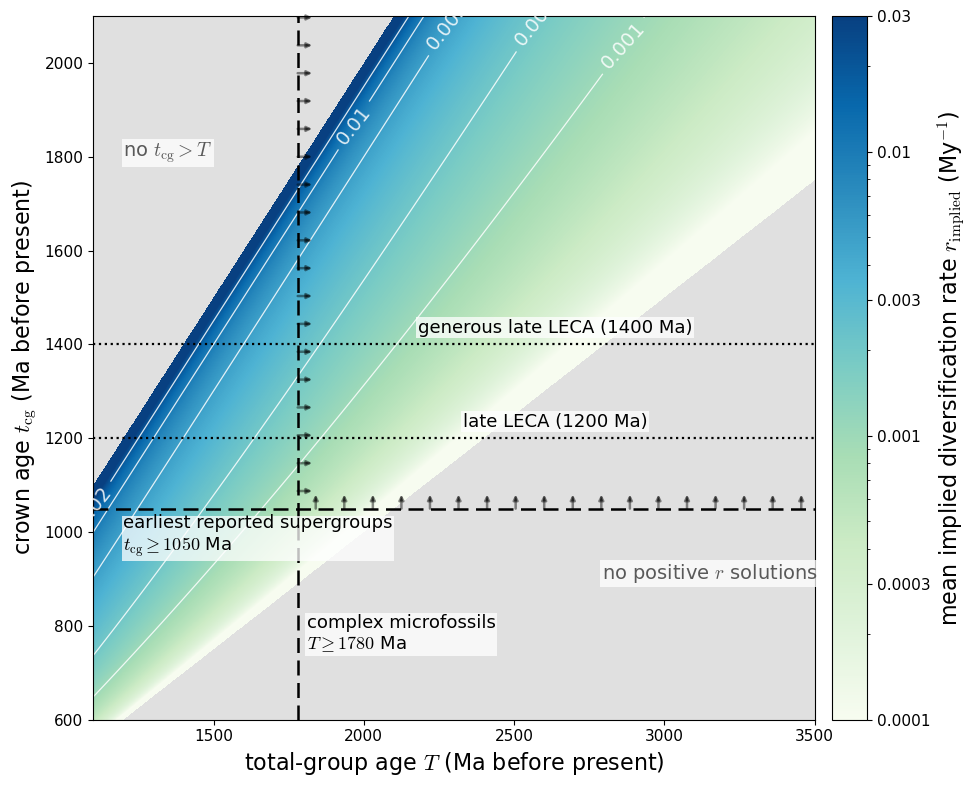

In [3]:
# ============================================================
# FIGURE 1 — mean implied diversification rate
# ============================================================
fig, ax = plt.subplots(figsize=(10, 8))

cmap = make_colormap(RATE_COLOUR_SCHEME)
Rm = np.ma.masked_invalid(R)
im = ax.pcolormesh(
    TT, CC, Rm,
    norm=LogNorm(vmin=1e-4, vmax=3e-2),
    cmap=cmap,
    shading="auto",
    rasterized=True,
)

# Rate contours
cs = ax.contour(
    TT, CC, R,
    levels=[1e-3, 2e-3, 5e-3, 1e-2, 2e-2],
    colors=CONTOUR_COLOUR,
    linewidths=0.9,
    alpha=0.85,
)
ax.clabel(
    cs,
    fmt={1e-3: "0.001", 2e-3: "0.002", 5e-3: "0.005",
         1e-2: "0.01", 2e-2: "0.02"},
    fontsize=14,
)

add_overlays(ax)
add_infeasible_annotations(ax)

ax.set_xlabel(r"total-group age $T$ (Ma before present)", fontsize=16)
ax.set_ylabel(r"crown age $t_{\mathrm{cg}}$ (Ma before present)", fontsize=16)

cb = fig.colorbar(im, ax=ax, pad=0.02)
cb.set_label(
    r"mean implied diversification rate $r_{\mathrm{implied}}$ (My$^{-1}$)",
    fontsize=16,
)
cb.set_ticks([1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2])
cb.set_ticklabels(["0.0001", "0.0003", "0.001", "0.003", "0.01", "0.03"])

ax.set_xlim(T_MIN, T_MAX)
ax.set_ylim(TCG_MIN, TCG_MAX)
fig.tight_layout()
fig.savefig("implied_rate_heatmap.pdf")           # vector, for the manuscript
# fig.savefig("implied_rate_heatmap.png", dpi=300)  # raster, for slides/email
plt.show()
plt.close(fig)


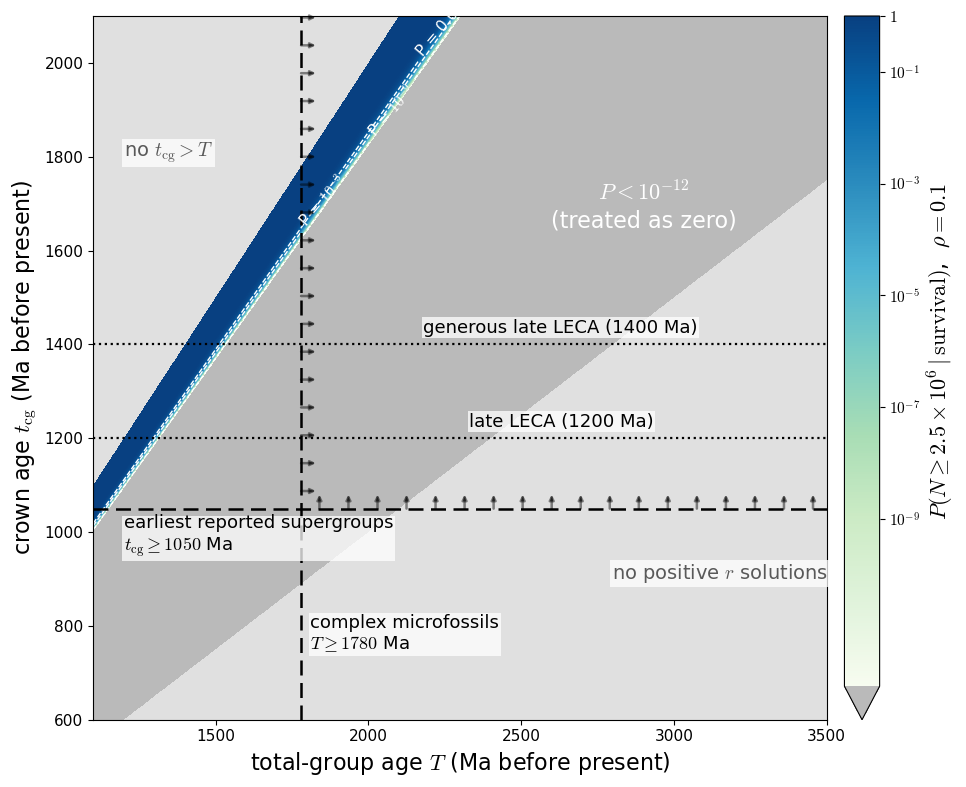

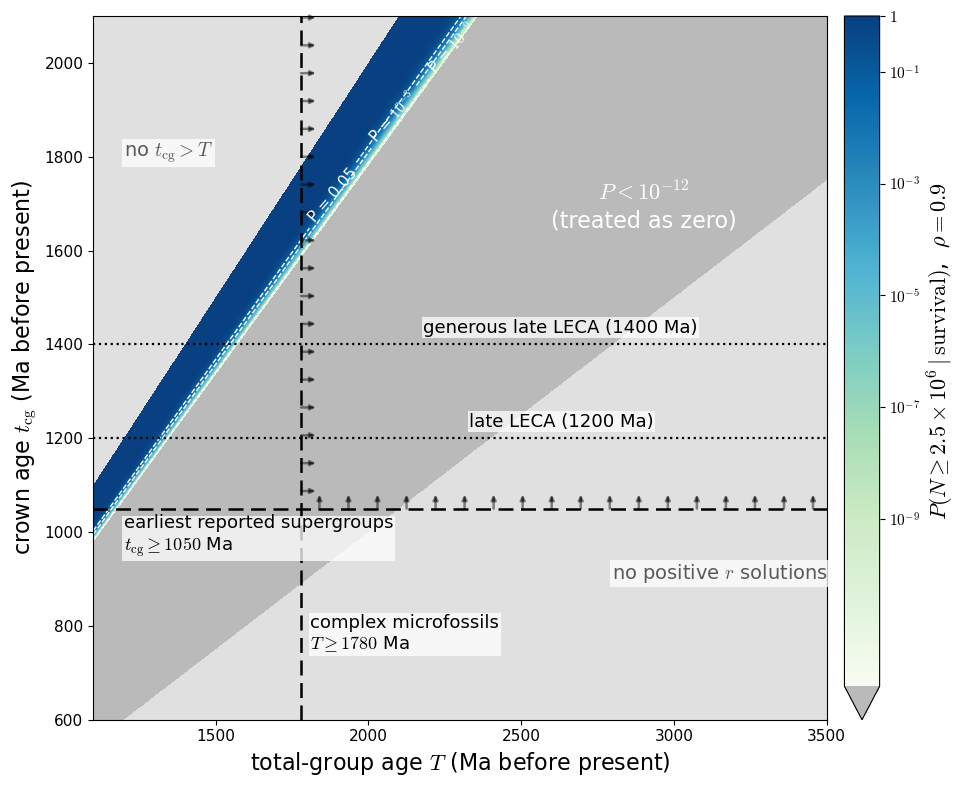

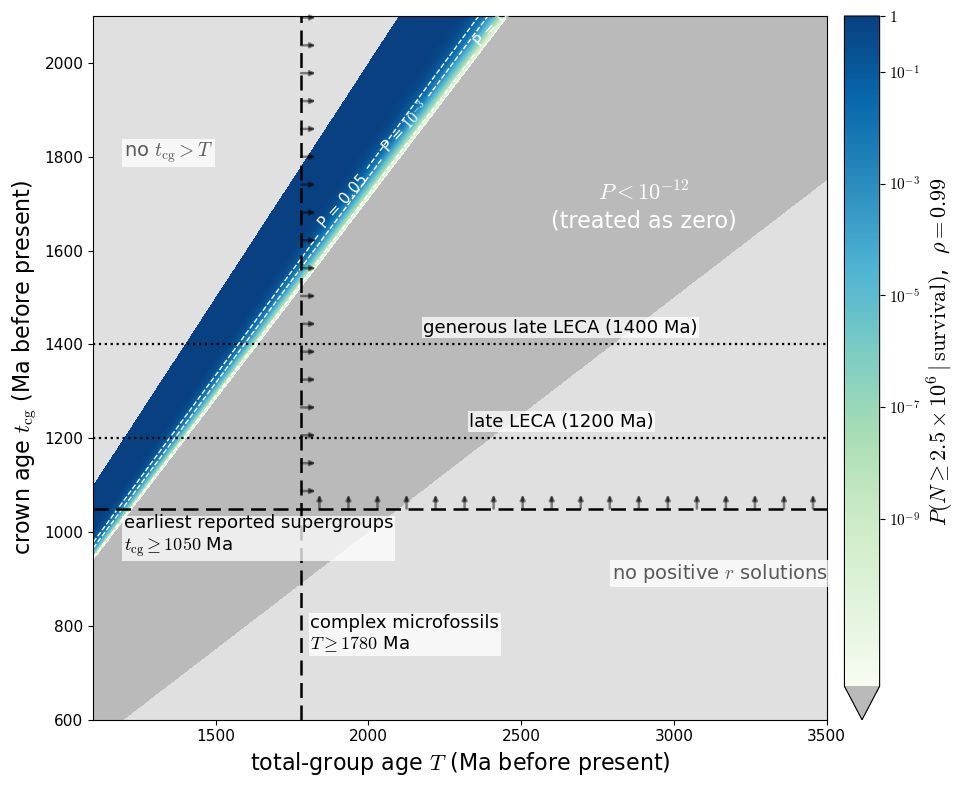

In [4]:
# ============================================================
# FIGURES 3 subpanels  — diversity probability at the implied rate
# ============================================================
for rho in RHOS:
    # P(N >= K_OBS | survival) = a_T^(K_OBS-1)
    # a_T = lam*(1 - e^{-rT})/(lam - mu*e^{-rT}) with lam = r/(1-rho), mu = rho*lam.
    # Computed in log space: P ~ 10^-10^6 in places, so never exponentiate raw.
    aT = (1 - np.exp(-R*TT)) / (1 - rho*np.exp(-R*TT))
    logP = (K_OBS - 1) * np.log10(aT)
    P = np.power(10.0, np.clip(logP, -300, 0))
    P[logP < np.log10(P_FLOOR)] = 0.5 * P_FLOOR
    Pm = np.ma.masked_invalid(P)

    fig, ax = plt.subplots(figsize=(10, 8))
    cmap = make_colormap(PROBABILITY_COLOUR_SCHEME, probability=True)
    im = ax.pcolormesh(
        TT, CC, Pm,
        norm=LogNorm(vmin=P_FLOOR, vmax=1.0),
        cmap=cmap,
        shading="auto",
        rasterized=True,
    )

    # Probability contours (levels must be increasing)
    cs = ax.contour(
        TT, CC, logP,
        levels=[-9, -3, np.log10(0.05)],
        colors=CONTOUR_COLOUR,
        linewidths=1.0,
        alpha=CONTOUR_ALPHA,
    )
    ax.clabel(
        cs,
        fmt={-9: "P = $10^{-9}$", -3: "P = $10^{-3}$",
             np.log10(0.05): "P = 0.05"},
        fontsize=11,
    )

    add_overlays(ax)
    add_infeasible_annotations(ax)
    ax.annotate(
        rf"$P < {latex_scientific(P_FLOOR)}$" + "\n(treated as zero)",
        xy=ZERO_PROBABILITY_XY,
        color=ZERO_PROBABILITY_TEXT_COLOUR,
        fontsize=16,
        ha="center",
    )

    ax.set_xlabel(r"total-group age $T$ (Ma before present)", fontsize=16)
    ax.set_ylabel(r"crown age $t_{\mathrm{cg}}$ (Ma before present)", fontsize=16)

    cb = fig.colorbar(im, ax=ax, pad=0.02, extend="min")
    cb.set_label(
        rf"$P(N \geq {latex_scientific(K_OBS)} \mid \mathrm{{survival}})$,  $\rho = {rho}$",
        fontsize=16,
    )
    cb.set_ticks([1e-9, 1e-7, 1e-5, 1e-3, 1e-1, 1])
    cb.set_ticklabels(["$10^{-9}$", "$10^{-7}$", "$10^{-5}$",
                       "$10^{-3}$", "$10^{-1}$", "$1$"])

    ax.set_xlim(T_MIN, T_MAX)
    ax.set_ylim(TCG_MIN, TCG_MAX)
    fig.tight_layout()
    fig.savefig(rf"diversity_probability_heatmap_rho_{rho}.pdf")
    # fig.savefig(rf"diversity_probability_heatmap_rho_{rho}.png", dpi=300)
    plt.show()
    plt.close(fig)


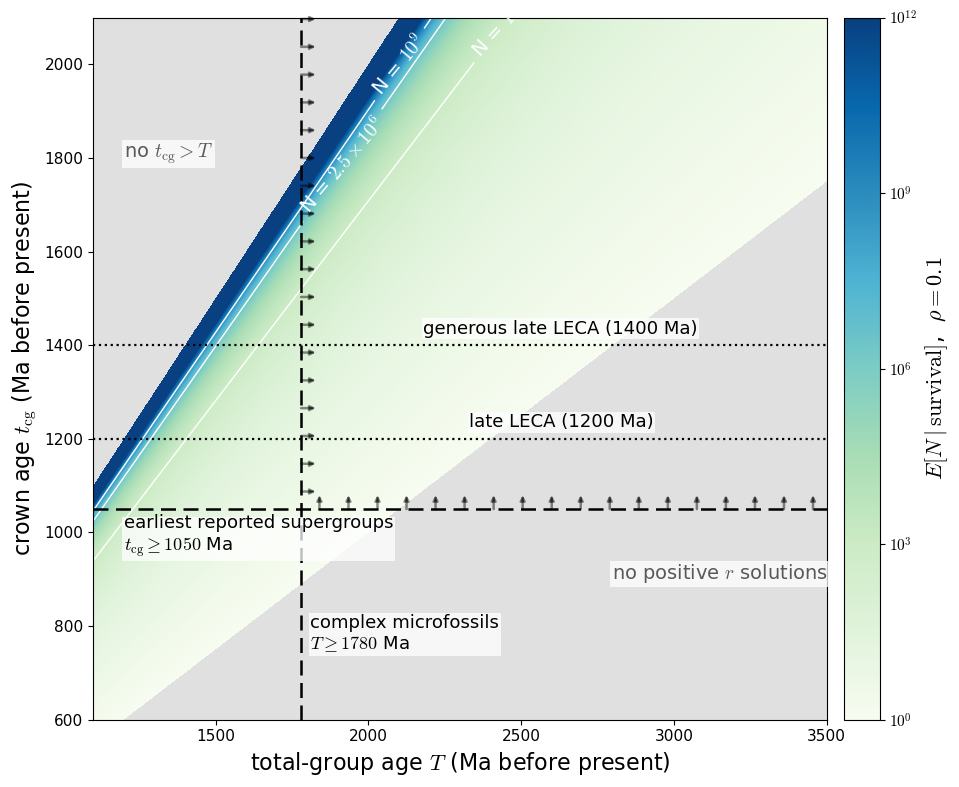

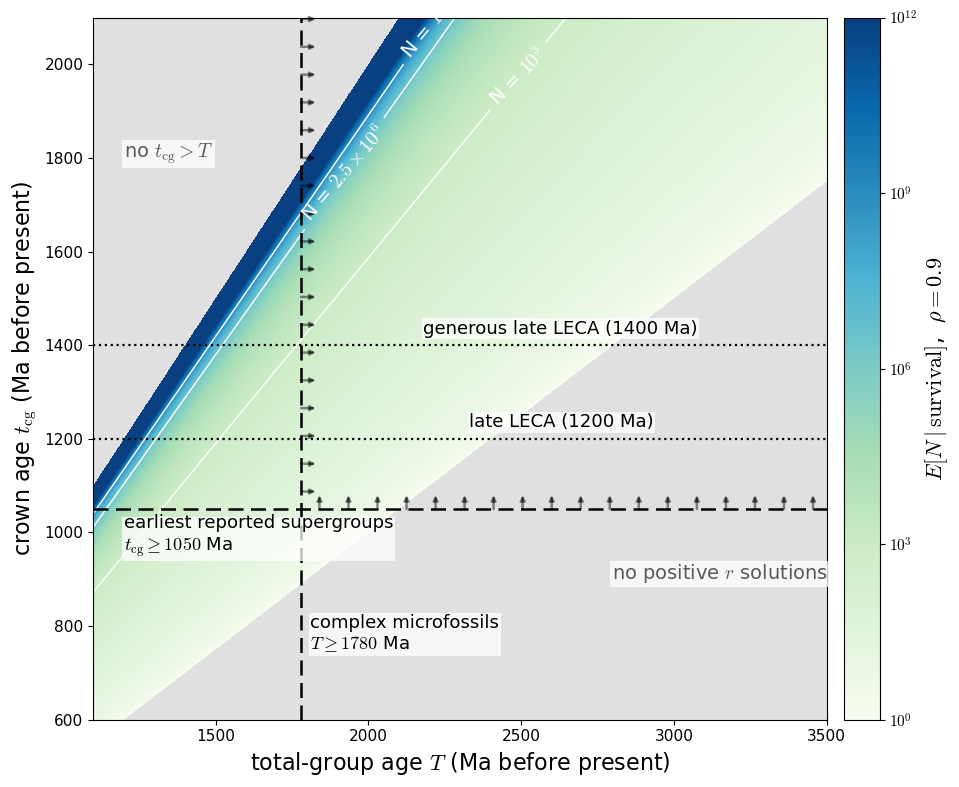

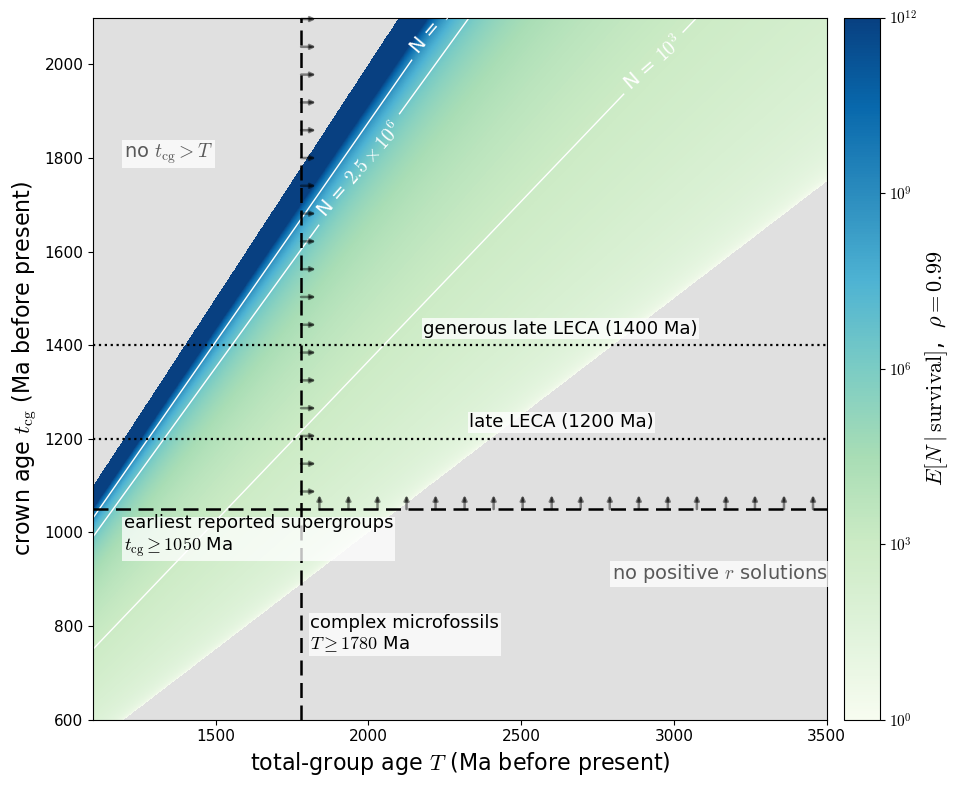

In [5]:
# ============================================================
# FIGURE 3 subpanels — expected living diversity at the implied rate
# ============================================================
for rho in RHOS:
    # E[N | survival] = e^{rT} (1 - rho e^{-rT}) / (1 - rho)
    # evaluated at r = r_implied. Computed in log space because e^{rT}
    # overflows float64 near the diagonal (rT can exceed 2000).
    logE = R*TT/np.log(10) + np.log10((1 - rho*np.exp(-R*TT))/(1 - rho))
    logEm = np.ma.masked_invalid(logE)

    fig, ax = plt.subplots(figsize=(10, 8))
    cmap = make_colormap(DIVERSITY_COLOUR_SCHEME)
    im = ax.pcolormesh(
        TT, CC, logEm,
        norm=Normalize(vmin=0, vmax=12),
        cmap=cmap,
        shading="auto",
        rasterized=True,
    )

    # Diversity contours (levels must be increasing)
    cs = ax.contour(
        TT, CC, logE,
        levels=[3, np.log10(K_OBS), 9],
        colors=CONTOUR_COLOUR,
        linewidths=1.0,
        alpha=CONTOUR_ALPHA,
    )
    ax.clabel(
        cs,
        fmt={3: "N = $10^3$",
             np.log10(K_OBS): rf"N = ${latex_scientific(K_OBS)}$",
             9: "N = $10^9$"},
        fontsize=14,
    )

    add_overlays(ax)
    add_infeasible_annotations(ax)

    ax.set_xlabel(r"total-group age $T$ (Ma before present)", fontsize=16)
    ax.set_ylabel(r"crown age $t_{\mathrm{cg}}$ (Ma before present)", fontsize=16)

    cb = fig.colorbar(im, ax=ax, pad=0.02)
    cb.set_label(rf"$E[N \mid \mathrm{{survival}}]$,  $\rho = {rho}$", fontsize=16)
    cb.set_ticks([0, 3, 6, 9, 12])
    cb.set_ticklabels(["$10^{0}$", "$10^{3}$", "$10^{6}$", "$10^{9}$", "$10^{12}$"])

    ax.set_xlim(T_MIN, T_MAX)
    ax.set_ylim(TCG_MIN, TCG_MAX)
    fig.tight_layout()
    fig.savefig(rf"expected_diversity_heatmap_rho_{rho}.pdf")
    # fig.savefig(rf"expected_diversity_heatmap_rho_{rho}.png", dpi=300)
    plt.show()
    plt.close(fig)


Saved: gap_tail_probability_rho_0.1.pdf and gap_tail_probability_rho_0.1.png


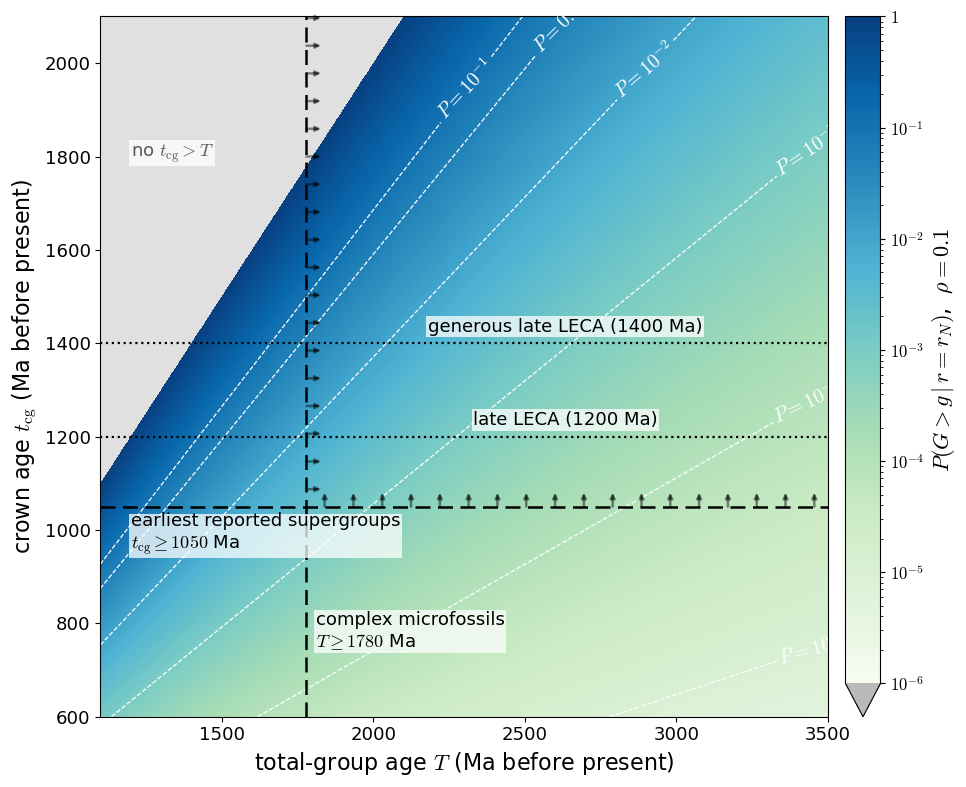

Saved: gap_tail_probability_rho_0.9.pdf and gap_tail_probability_rho_0.9.png


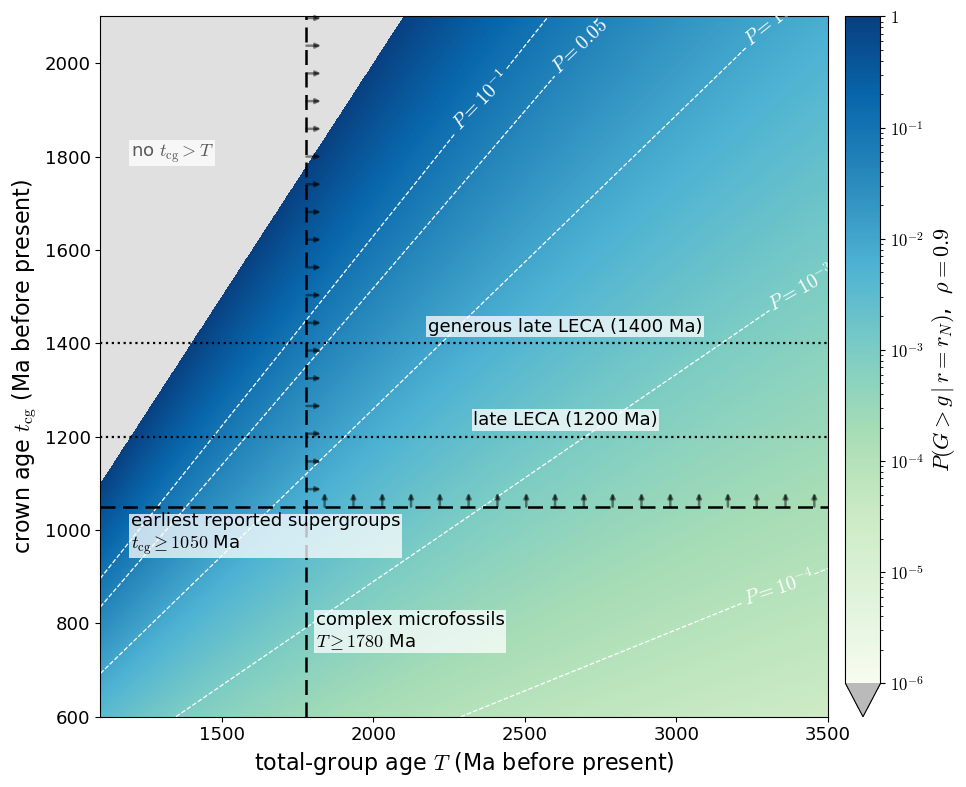

Saved: gap_tail_probability_rho_0.99.pdf and gap_tail_probability_rho_0.99.png


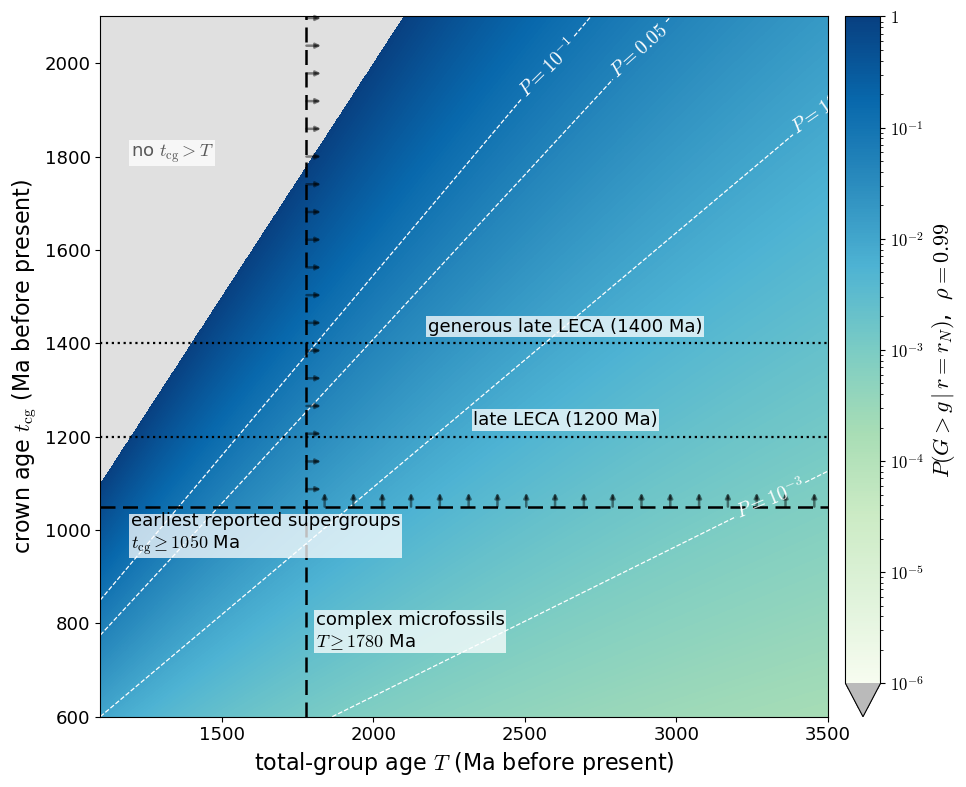

In [6]:
# ============================================================
# FIGURES 4 subpanels — gap tail probability at r = r_N
# ============================================================
G = TT - CC

for rho in RHOS:
    # Calculate the exact tail probability.
    Q = rho + (1.0 - rho) * N_OBS
    logQ = np.log(Q)
    x = G / TT  # g/T

    # P(G > g | r = r_N)
    # = [Q^(-g/T) - Q^(-1)] / [1 - Q^(-1)]
    # Evaluated in log space for numerical stability.
    with np.errstate(divide="ignore", invalid="ignore"):
        logP_nat = (
            -x * logQ
            + np.log1p(-np.exp(-(1.0 - x) * logQ))
            - np.log1p(-np.exp(-logQ))
        )

    logP = logP_nat / np.log(10.0)
    logP[G <= 0] = np.nan  # exclude t_cg >= T

    P = np.power(10.0, np.clip(logP, -300, 0))
    P[logP < np.log10(GAP_P_FLOOR)] = 0.5 * GAP_P_FLOOR
    Pm = np.ma.masked_invalid(P)

    # Create an individual figure.
    fig, ax = plt.subplots(figsize=(10, 8))
    cmap = make_colormap(GAP_PROBABILITY_COLOUR_SCHEME, probability=True)
    im = ax.pcolormesh(
        TT, CC, Pm,
        norm=LogNorm(vmin=GAP_P_FLOOR, vmax=1.0),
        cmap=cmap,
        shading="auto",
        rasterized=True,
    )

    # Probability contours
    possible_levels = [-6, -5, -4, -3, -2, np.log10(0.05), -1]
    finite_logP = logP[np.isfinite(logP)]
    levels = [
        level for level in possible_levels
        if finite_logP.min() < level < finite_logP.max()
    ]

    if levels:
        cs = ax.contour(
            TT, CC, logP,
            levels=levels,
            colors=CONTOUR_COLOUR,
            linewidths=0.9,
            alpha=CONTOUR_ALPHA,
        )

        def contour_fmt(level):
            if np.isclose(level, np.log10(0.05)):
                return r"$P = 0.05$"
            return rf"$P = 10^{{{int(round(level))}}}$"

        ax.clabel(
            cs,
            fmt=contour_fmt,
            fontsize=14,
            inline=True,
            inline_spacing=3,
        )

    add_overlays(ax, fontsize=13)
    add_infeasible_annotations(ax, include_no_solution=False, fontsize=13)

    # Axes and colour bar
    ax.set_xlabel(r"total-group age $T$ (Ma before present)", fontsize=16)
    ax.set_ylabel(r"crown age $t_{\mathrm{cg}}$ (Ma before present)", fontsize=16)
    ax.tick_params(axis="both", labelsize=13)
    ax.set_xlim(T_MIN, T_MAX)
    ax.set_ylim(TCG_MIN, TCG_MAX)

    cb = fig.colorbar(im, ax=ax, pad=0.02, extend="min")
    cb.set_label(rf"$P(G>g \mid r=r_N)$,  $\rho = {rho}$", fontsize=16)
    cb.set_ticks([1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1])
    cb.set_ticklabels([
        r"$10^{-6}$", r"$10^{-5}$", r"$10^{-4}$",
        r"$10^{-3}$", r"$10^{-2}$", r"$10^{-1}$", r"$1$",
    ])
    cb.ax.tick_params(labelsize=12)

    fig.tight_layout()

    # Save each figure individually using the original naming convention.
    pdf_name = f"gap_tail_probability_rho_{rho}.pdf"
    png_name = f"gap_tail_probability_rho_{rho}.png"
    fig.savefig(pdf_name, bbox_inches="tight")
    fig.savefig(png_name, dpi=300, bbox_inches="tight")
    print(f"Saved: {pdf_name} and {png_name}")

    plt.show()
    plt.close(fig)


In [7]:

# ============================================================
# RATE CHANGE — mean-gap implied rate vs post-LECA rate
# ============================================================

# Scenario ages (Ma before present)
T_TOTAL_RATE_CHANGE = 1800.0
T_CG_RATE_CHANGE = 1100.0

# Compare one founding lineage with two crown daughter lineages.
# For two lineages, both are assumed to survive to the present.
CROWN_STARTS_TO_COMPARE = [1, 2]

# Include pure birth (rho = 0) and configured turnover values.
RATE_CHANGE_RHOS = sorted(set([0.0] + list(RHOS)))

# ---- Exact mean-gap implied rate ----
GAP_RATE_CHANGE = T_TOTAL_RATE_CHANGE - T_CG_RATE_CHANGE

R_GAP = r_implied(
    T_TOTAL_RATE_CHANGE,
    T_CG_RATE_CHANGE
)

if not np.isfinite(R_GAP):
    raise ValueError("No positive mean-gap implied rate for this scenario.")

# Large-rT approximation, for comparison only.
R_GAP_APPROX = 1.0 / GAP_RATE_CHANGE


# ---- Calculate post-LECA diversification rates ----
# From E[N | survival] = (exp(r*t) - rho)/(1-rho).
#
# With m independently surviving founding lineages:
#
# N_OBS = m * (exp(r*t) - rho)/(1-rho)
#
# Rearranging gives the exact expression below.

print("=" * 72)
print("RATE CHANGE SCENARIO")
print("=" * 72)

print(f"Total-group age:              {T_TOTAL_RATE_CHANGE:.0f} Ma")
print(f"Crown-group age:               {T_CG_RATE_CHANGE:.0f} Ma")
print(f"Stem-crown gap:                {GAP_RATE_CHANGE:.0f} Ma")
print(f"Modern diversity:              {N_OBS:,.0f} species")
print()
print(f"Exact mean-gap implied rate:   {R_GAP:.6g} My-1")
print(f"Corresponding rT:              {R_GAP * T_TOTAL_RATE_CHANGE:.4f}")
print()
print(f"Large-rT approximation:        {R_GAP_APPROX:.6g} My-1")

# Check how well the large-rT approximation actually performs.
x_approx = R_GAP_APPROX * T_TOTAL_RATE_CHANGE
gap_from_approx = (
    1.0 / R_GAP_APPROX
    - T_TOTAL_RATE_CHANGE * np.exp(-x_approx)
    / (-np.expm1(-x_approx))
)

print(f"Mean gap at approximate rate:  {gap_from_approx:.2f} Ma")
print()
print("-" * 72)
print(
    f"{'rho':>6} {'Founders':>9} {'r_post (My-1)':>17} "
    f"{'Rate ratio':>13} {'Increase':>12}"
)
print("-" * 72)

for rho in RATE_CHANGE_RHOS:

    if not (0.0 <= rho < 1.0):
        raise ValueError(f"Invalid turnover value: {rho}")

    for n_start in CROWN_STARTS_TO_COMPARE:

        # Exact rate required to reach observed diversity.
        R_POST = (
            np.log(
                rho + (1.0 - rho) * N_OBS / n_start
            ) / T_CG_RATE_CHANGE
        )

        # Compare with the exact mean-gap implied rate.
        RATE_RATIO = R_POST / R_GAP
        RATE_INCREASE = (RATE_RATIO - 1.0) * 100.0

        print(
            f"{rho:6.2f} {n_start:9d} {R_POST:17.6g} "
            f"{RATE_RATIO:12.2f}x {RATE_INCREASE:11.1f}%"
        )

print("-" * 72)
print()
print("Rates are net diversification rates r = lambda - mu.")
print("The one-founder calculation reproduces the manuscript's")
print("single-founder comparison; two founders represent the")
print("two surviving daughter lineages of the crown bifurcation.")


RATE CHANGE SCENARIO
Total-group age:              1800 Ma
Crown-group age:               1100 Ma
Stem-crown gap:                700 Ma
Modern diversity:              2,500,000 species

Exact mean-gap implied rate:   0.000763766 My-1
Corresponding rT:              1.3748

Large-rT approximation:        0.00142857 My-1
Mean gap at approximate rate:  551.05 Ma

------------------------------------------------------------------------
   rho  Founders     r_post (My-1)    Rate ratio     Increase
------------------------------------------------------------------------
  0.00         1         0.0133925        17.53x      1653.5%
  0.00         2         0.0127624        16.71x      1571.0%
  0.10         1         0.0132968        17.41x      1640.9%
  0.10         2         0.0126666        16.58x      1558.4%
  0.90         1         0.0112993        14.79x      1379.4%
  0.90         2         0.0106692        13.97x      1296.9%
  0.99         1        0.00920606        12.05x      1105